正在进行情感分析，由于数据量有 8 万多条，请耐心等待...

===== 情感分布统计 =====
sentiment
负面    74264
中性     5453
正面     4535
Name: count, dtype: int64


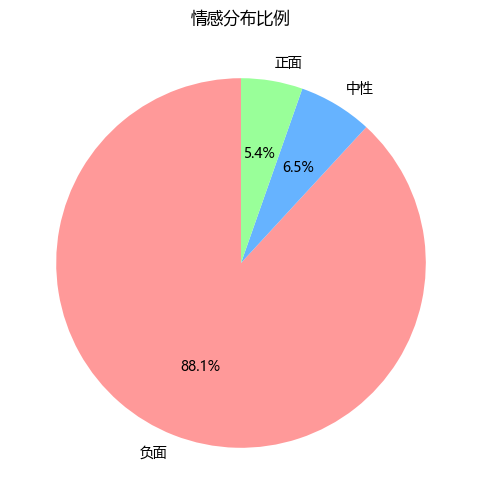

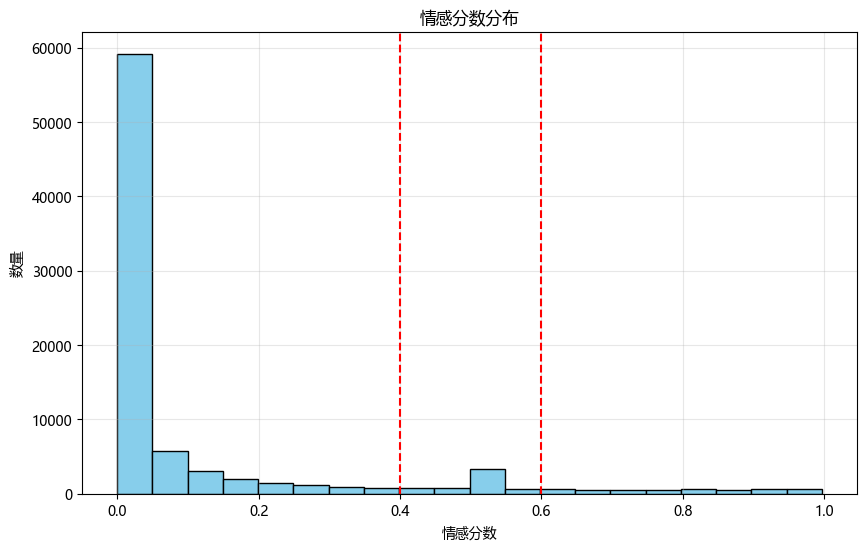


✅ 情感分布数据已成功保存至: D:\桌面\项目材料\基于Dify工作流的聊天助手搭建及智能数据分析项目\聊天助手\情感分布.csv


In [2]:
from snownlp import SnowNLP
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

# 1. 定义情感分析函数（直接处理原始字符串）
def analyze_sentiment(text):
    try:
        # 过滤掉空值
        if not isinstance(text, str) or text.strip() == "":
            return 0.5
        return SnowNLP(text).sentiments
    except:
        return 0.5

print("正在进行情感分析，由于数据量有 8 万多条，请耐心等待...")

# 2. 直接对 records 列进行情感打分
df['sentiment_score'] = df['records'].apply(analyze_sentiment)

# 3. 情感分类
df['sentiment'] = pd.cut(
    df['sentiment_score'],
    bins=[0, 0.4, 0.6, 1],
    labels=['负面', '中性', '正面'],
    right=False
)

# 4. 查看分布
print("\n===== 情感分布统计 =====")
print(df['sentiment'].value_counts())

# 5. 可视化分析结果
rcParams['font.sans-serif'] = ['Microsoft YaHei']
rcParams['axes.unicode_minus'] = False

# 5.1 情感分布饼图
plt.figure(figsize=(8, 6))
df['sentiment'].value_counts().plot.pie(
    autopct='%1.1f%%',
    colors=['#ff9999', '#66b3ff', '#99ff99'],
    startangle=90
)
plt.title('情感分布比例')
plt.ylabel('')
plt.show()

# 5.2 情感分数分布直方图
plt.figure(figsize=(10, 6))
plt.hist(
    df['sentiment_score'],
    bins=20,
    color='skyblue',
    edgecolor='black'
)
plt.axvline(0.4, color='red', linestyle='--')
plt.axvline(0.6, color='red', linestyle='--')
plt.title('情感分数分布')
plt.xlabel('情感分数')
plt.ylabel('数量')
plt.grid(alpha=0.3)
plt.show()

# 6. 保存数据
sentiment_df = pd.DataFrame({
    '情感': df['sentiment'].value_counts().index,
    '数量': df['sentiment'].value_counts().values
})

save_path = 'D:\桌面\项目材料\基于Dify工作流的聊天助手搭建及智能数据分析项目\聊天助手\情感分布.csv' # 你可以自己改路径
sentiment_df.to_csv(save_path, index=False, encoding='utf-8-sig')
print(f"\n✅ 情感分布数据已成功保存至: {save_path}")